# Visibility models

This tutorial shows how `BinaryModelCartesian` and `BinaryModelAngular` work internally, how they interact with `OIData`, and how a likelihood is built from an `OIData` instance and a model class.

## Introduce the visibility model parameterizations

We define the Cartesian and angular binary models on the same baseline geometry, and check that they give equivalent complex visibilities when the parameters are converted consistently.

In [ ]:
import warnings

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from virgil.likelihood import loglike
from virgil.limits import flux_to_contrast, flux_to_delta_mag
from virgil.models import BinaryModelAngular, BinaryModelCartesian
from virgil.oidata import OIData
from virgil.plotting import set_style

warnings.filterwarnings("ignore", category=SyntaxWarning)  # upstream zodiax docstrings
set_style()  # the figure style used throughout the docs


def round_floats(x, sig=4):
    """Round printed floats to a few significant figures (float32 noise)."""
    if isinstance(x, float):
        return float(f"{x:.{sig}g}")
    if isinstance(x, dict):
        return {k: round_floats(v, sig) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return type(x)(round_floats(v, sig) for v in x)
    return x


## Generate OIData from models

Next we generate synthetic observables from the Cartesian model and package them into an `OIData` instance.

A model is a *parametrized function*: it takes parameters such as sep, pa and flux and builds an object, say `model`, that you can apply to data. Calling `model.model(u, v, wavel)` evaluates the complex visibilities at those coordinates.

In [ ]:
rng = np.random.default_rng(21)
u = jnp.array(rng.uniform(-30.0, 30.0, size=24))
v = jnp.array(rng.uniform(-30.0, 30.0, size=24))
wavel = jnp.array([4.8e-6])

truth_cart = {"dra": 120.0, "ddec": -80.0, "flux": 4e-3}
model_cart_true = BinaryModelCartesian(**truth_cart)

dra = float(truth_cart["dra"])
ddec = float(truth_cart["ddec"])
flux = float(truth_cart["flux"])
sep = float(np.sqrt(dra**2 + ddec**2))
pa = float((np.degrees(np.arctan2(dra, ddec)) + 360.0) % 360.0)
model_ang = BinaryModelAngular(sep=sep, pa=pa, flux=flux)

cvis_true = model_cart_true.model(u, v, wavel)
cvis_ang = model_ang.model(u, v, wavel)
max_complex_diff = float(np.max(np.abs(np.asarray(cvis_ang - cvis_true))))

round_floats({
    "cartesian": truth_cart,
    "angular": {"sep": sep, "pa": pa, "flux": flux},
    "max_complex_visibility_difference": max_complex_diff,
})


`OIData` stores observables, uncertainties and convention flags (`v2_flag` and `cp_flag`), so that model outputs can be converted and flattened consistently. It flattens the data into vectors and tracks which kind of observable each one is.

In [3]:
vis_true = jnp.abs(cvis_true) ** 2
phi_true = jnp.rad2deg(jnp.angle(cvis_true))

d_vis = (
    0.002 * jnp.maximum(jnp.median(vis_true), 1e-6) * jnp.ones_like(vis_true)
)
d_phi = (
    0.01
    * jnp.maximum(jnp.median(jnp.abs(phi_true)), 5.0)
    * jnp.ones_like(phi_true)
)

vis_obs = vis_true + d_vis * jnp.array(rng.normal(size=vis_true.shape))
phi_obs = phi_true + d_phi * jnp.array(rng.normal(size=phi_true.shape))

data = OIData(
    {
        "u": u,
        "v": v,
        "wavel": wavel,
        "vis": vis_obs,
        "d_vis": d_vis,
        "phi": phi_obs,
        "d_phi": d_phi,
        "phi_unit": "deg",
        "i_cps1": None,
        "i_cps2": None,
        "i_cps3": None,
        "v2_flag": True,
        "cp_flag": False,
    }
)

{
    "n_baselines": int(data.u.shape[0]),
    "v2_flag": bool(data.v2_flag),
    "cp_flag": bool(data.cp_flag),
}

{'n_baselines': 24, 'v2_flag': True, 'cp_flag': False}

## How `OIData.model(...)` builds comparable vectors

`OIData.model(model)` evaluates complex visibilities through the model, converts them to the configured observables (`V²` and phases here), and flattens them to match `OIData.flatten_data()`.

In [4]:
model_vector = data.model(model_cart_true)
data_vector, err_vector = data.flatten_data()

{
    "model_len": int(model_vector.shape[0]),
    "data_len": int(data_vector.shape[0]),
    "error_len": int(err_vector.shape[0]),
    "vector_alignment": bool(
        model_vector.shape == data_vector.shape == err_vector.shape
    ),
}

{'model_len': 48, 'data_len': 48, 'error_len': 48, 'vector_alignment': True}

## Cartesian vs angular parameter conversions

The Cartesian model uses $(\Delta\mathrm{RA},\Delta\mathrm{Dec}, f)$, where $f$ is the companion/primary flux ratio.
The angular model uses $(\rho,\mathrm{PA}, f)$ with the same flux ratio. The conversion is:

$$
\rho = \sqrt{\Delta\mathrm{RA}^2 + \Delta\mathrm{Dec}^2}, \quad
\mathrm{PA} = \mathrm{atan2}(\Delta\mathrm{RA}, \Delta\mathrm{Dec})
$$

Results are usually reported as a contrast $C = 1/f$ (primary/companion) or $\Delta m = 2.5 \log_{10} C$: a companion 100 times fainter has $f = 0.01$, $C = 100$ and $\Delta m = 5$ mag. `virgil.limits.flux_to_contrast` and `flux_to_delta_mag` do the conversion.

In [ ]:
dra = float(truth_cart["dra"])
ddec = float(truth_cart["ddec"])
flux = float(truth_cart["flux"])

sep = float(np.sqrt(dra**2 + ddec**2))
pa = float((np.degrees(np.arctan2(dra, ddec)) + 360.0) % 360.0)
model_ang = BinaryModelAngular(sep=sep, pa=pa, flux=flux)
cvis_ang = model_ang.model(u, v, wavel)
max_complex_diff = float(np.max(np.abs(np.asarray(cvis_ang - cvis_true))))

round_floats({
    "sep_mas": sep,
    "pa_deg": pa,
    "flux": flux,
    # Reported the astronomical way: primary/companion, and in magnitudes.
    "contrast": float(flux_to_contrast(flux)),
    "delta_mag": float(flux_to_delta_mag(flux)),
    "max_complex_visibility_difference": max_complex_diff,
})


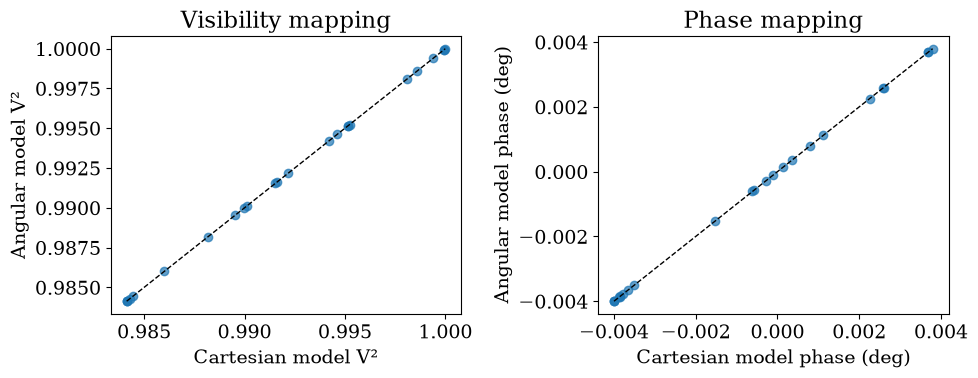

In [6]:
vis_cart = np.asarray(data.to_vis(cvis_true))
vis_ang = np.asarray(data.to_vis(cvis_ang))
phi_cart = np.asarray(data.to_phases(cvis_true))
phi_ang = np.asarray(data.to_phases(cvis_ang))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.scatter(vis_cart, vis_ang, alpha=0.7)
line_v = np.linspace(
    min(vis_cart.min(), vis_ang.min()), max(vis_cart.max(), vis_ang.max()), 100
)
ax1.plot(line_v, line_v, "k--", lw=1)
ax1.set_xlabel("Cartesian model V²")
ax1.set_ylabel("Angular model V²")
ax1.set_title("Visibility mapping")

ax2.scatter(phi_cart, phi_ang, alpha=0.7)
line_p = np.linspace(
    min(phi_cart.min(), phi_ang.min()), max(phi_cart.max(), phi_ang.max()), 100
)
ax2.plot(line_p, line_p, "k--", lw=1)
ax2.set_xlabel("Cartesian model phase (deg)")
ax2.set_ylabel("Angular model phase (deg)")
ax2.set_title("Phase mapping")

plt.tight_layout()
plt.show()

## Likelihood wiring from `OIData` + model class

`loglike(values, params, model, data)` zips parameter names to values and instantiates `model(**param_dict)` (for a template model instance, it sets the leaves at those paths instead). It then evaluates `data.model(...)` and compares the result to the flattened data with Gaussian errors.

In [ ]:
params_cart = ["dra", "ddec", "flux"]
vals_cart = [dra, ddec, flux]
ll_cart = float(loglike(vals_cart, params_cart, BinaryModelCartesian, data))

params_ang = ["sep", "pa", "flux"]
vals_ang = [sep, pa, flux]
ll_ang = float(loglike(vals_ang, params_ang, BinaryModelAngular, data))

ll_cart_perturbed = float(
    loglike(
        [dra + 20.0, ddec - 20.0, flux * 1.6],
        params_cart,
        BinaryModelCartesian,
        data,
    )
)

round_floats({
    "ll_cart_true": ll_cart,
    "ll_ang_equivalent": ll_ang,
    "ll_cart_perturbed": ll_cart_perturbed,
    "true_beats_perturbed": bool(ll_cart > ll_cart_perturbed),
})


So model classes define the parameter syntax and complex visibilities, `OIData` defines observable conventions and flattening, and `loglike` joins the two for inference.